In [48]:
import re
import unicodedata
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
raw = pd.read_csv("data/raw/raw.csv")

In [10]:
raw.head(1)

,id_artikel,keyword,url,timestamp,judul,isi_mentah
0,777827,BCA,https://www.cnbcindonesia.com/market/202610201...,2026-10-20,"Aksi Jual Asing Rp1,97 T di Sesi I, Saham BCA ...",Indeks Harga Saham Gabungan (IHSG) berhasil me...


In [11]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3979 entries, 0 to 3978
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_artikel  3979 non-null   int64 
 1   keyword     3979 non-null   object
 2   url         3979 non-null   object
 3   timestamp   3979 non-null   object
 4   judul       3979 non-null   object
 5   isi_mentah  3979 non-null   object
dtypes: int64(1), object(5)
memory usage: 186.6+ KB


## **Pecah kalimat per artikel**

In [19]:
# aturan split per kalimat
singkatan = ["PT", "Tbk", "Persero", "Rp", "US", "No", "Jl", "Dr", "Ir", "Hj",
             "Prof", "Sdr", "S.E", "M.M", "Ph.D", "dll", "dsb", "dkk", "a.l", "yakni"]
split = re.compile(r'(?<=[.!?])\s+|(?<=[.!?]["\u201d])\s+')

def pecah_kalimat(teks):
    t = re.sub(r"\s+", " ", str(teks)).strip()
    for ab in singkatan:
        t = re.sub(rf"\b{re.escape(ab)}\.", lambda m: m.group(0)[:-1] + "<DOT>", t)
    t = re.sub(r"\b([A-Z])\.(?=\s)", r"\1<DOT>", t)
    t = re.sub(r"(?<=\d)\.(?=\d)", "<DOT>", t)
    return [x.replace("<DOT>", ".").strip() for x in split.split(t) if x.strip()]

In [18]:
rows_kalimat = []

for row in raw.itertuples(index=False):

    kalimat_list = pecah_kalimat(row.isi_mentah)

    for i, kalimat in enumerate(kalimat_list):

        rows_kalimat.append({
            "id_artikel": row.id_artikel,
            "id_kalimat": f"{row.id_artikel}_{i}",
            "judul": row.judul,
            "timestamp": row.timestamp,
            "kalimat": kalimat
        })

df_kalimat = pd.DataFrame(rows_kalimat)

print(f"Jumlah artikel       : {len(raw):,}")
print(f"Jumlah kalimat      : {len(df_kalimat):,}")
print(f"Rata-rata kalimat/artikel: {len(df_kalimat) / max(len(raw), 1):.2f}")


Jumlah artikel       : 3,979
Jumlah kalimat      : 82,509
Rata-rata kalimat/artikel: 20.74


In [20]:
def cek_fulltext(df, text, n=5, mode="head", random_state=42):
    if text not in df.columns:
        raise ValueError(f"Kolom '{text}' tidak ditemukan.")

    if n <= 0:
        raise ValueError("n harus lebih besar dari 0.")

    if mode not in {"head", "tail", "sample"}:
        raise ValueError("mode harus head, tail, atau sample.")

    n = min(n, len(df))

    if mode == "head":
        hasil = df.head(n)

    elif mode == "tail":
        hasil = df.tail(n)

    else:
        hasil = df.sample(
            n=n,
            random_state=random_state
        )

    kolom = [
        col for col in
        ["id_artikel", "judul", "timestamp", text]
        if col in df.columns
    ]

    for _, row in hasil[kolom].iterrows():
        print("=" * 100)

        if "id_artikel" in row:
            print(f"ID       : {row['id_artikel']}")

        if "judul" in row:
            print(f"Judul    : {row['judul']}")

        if "timestamp" in row:
            print(f"Timestamp: {row['timestamp']}")

        print(f"\nFulltext:\n{row[text]}\n")

In [22]:
cek_fulltext(df_kalimat, "kalimat", 5, "head")

ID       : 777827
Judul    : Aksi Jual Asing Rp1,97 T di Sesi I, Saham BCA Paling Banyak Dibuang
Timestamp: 2026-10-20

Fulltext:
Indeks Harga Saham Gabungan (IHSG) berhasil mengakhiri perdagangan sesi I hari ini, Selasa (20/10/2026), di zona hijau.

ID       : 777827
Judul    : Aksi Jual Asing Rp1,97 T di Sesi I, Saham BCA Paling Banyak Dibuang
Timestamp: 2026-10-20

Fulltext:
IHSG ditutup di level 5.204,63, naik 208,02 poin atau 4,16%.

ID       : 777827
Judul    : Aksi Jual Asing Rp1,97 T di Sesi I, Saham BCA Paling Banyak Dibuang
Timestamp: 2026-10-20

Fulltext:
Namun, asing masih saja mencatatkan penjualan dengan nilai yang cukup besar.

ID       : 777827
Judul    : Aksi Jual Asing Rp1,97 T di Sesi I, Saham BCA Paling Banyak Dibuang
Timestamp: 2026-10-20

Fulltext:
Investor asing mencatatkan net sell sebesar Rp1,97 triliun di seluruh pasar pada akhir sesi I perdagangan Selasa ini.

ID       : 777827
Judul    : Aksi Jual Asing Rp1,97 T di Sesi I, Saham BCA Paling Banyak Dibuang
Tim

## **Exploratory Data Analysis & Preprocessing**

### **Noise / Boilerplate yang terlewat**

In [31]:
dateline   = re.compile(r'^\s*(?:jakarta\s*,?\s*)?cnbc\s+indonesia\s*[-\u2013\u2014:]\s*', re.I)
url        = re.compile(r'(?i)\b(?:https?://|www\.)[^\s<>"\u201d]+')
invisible  = re.compile('[\u200b\u200c\u200d\u200e\u200f\u2060\ufeff]')
footer     = re.compile(r'^(?:cnbc\s+indonesia\s+research(?:\s+market@cnbcindonesia\.com)?|selamat\s+berinvestasi\s+secara\s+bijak)[.!\s]*$', re.I)
link_promo = re.compile(r'(?i)(?:baca\s+artikel\s+cnbc\s+indonesia|selengkapnya\s+di\s+sini).*(?:cnbcindonesia\.com|download\s+apps\s+cnbc)')
disclaimer = re.compile(r"^keputusan berinvestasi sepenuhnya berada di tangan masing-masing investor sesuai dengan profil risiko dan tujuan keuangan pribadi[.!\s]*$", re.I)
fragment   = re.compile(r"^(?:ltd\.?|\(?dok\.?)$", re.I)
numeric    = re.compile(r'^[\W\d_]+$', re.UNICODE)
noise     = re.compile(r"CNBC\s*INDONESIA\s*RESEARCH|market@cnbcindonesia\.com|\bNEXT\b|Lihat\s*juga|Saksikan\s+(?:Video|juga)|\bBaca\s*:|^Foto\s*:|^Infografis\s*:|\[Gambas:|\bBaca\s+(?:juga|artikel)\b", re.I)

In [32]:
pola_analisis = {
    "Link promo": link_promo,
    "Dateline": dateline,
    "URL": url,
    "Footer": footer,
    "Disclaimer": disclaimer,
    "Fragment": fragment,
    "numeric": numeric,
    "Noise": noise,
}

hasil_analisis = []

for nama, pola in pola_analisis.items():

    cocok = df_kalimat["kalimat"].astype(str).apply(
        lambda x: bool(pola.search(x))
    )

    hasil_analisis.append({
        "pola": nama,
        "jumlah_terdeteksi": cocok.sum(),
        "persentase": round(cocok.mean() * 100, 2)
    })

analisis_regex = pd.DataFrame(hasil_analisis)

analisis_regex.sort_values(
    "jumlah_terdeteksi",
    ascending=False
)

,pola,jumlah_terdeteksi,persentase
6,numeric,425,0.52
3,Footer,170,0.21
7,Noise,155,0.19
4,Disclaimer,47,0.06
1,Dateline,35,0.04
2,URL,35,0.04
5,Fragment,30,0.04
0,Link promo,7,0.01


In [30]:
def cek_pola(df, pola, n=10, random_state=42):

    cocok = df[
        df["kalimat"].astype(str).apply(
            lambda x: bool(pola.search(x))
        )
    ]

    if cocok.empty:
        print("Tidak ada kalimat yang cocok.")
        return

    return cocok.sample(
        min(n, len(cocok)),
        random_state=random_state
    )[["id_artikel", "judul", "kalimat"]]


cek_pola(df_kalimat, numeric, n=10)

,id_artikel,judul,kalimat
77995,731619,Skor Kredit Jelek? Begini Cara Bersihkan Nama ...,2.
7531,624731,"Daftar 16 Emiten yang Buyback Tanpa RUPS, Ada ...",5.
12511,776395,"IHSG Anjlok 2%, Ini Penyebabnya",4.
4378,691946,Sosok 9 Pemilik Mal Raksasa di Jakarta,3.
63555,645094,"Dana Asing Kabur Rp 358,73 M, Saham Ini Banyak...",1.
55703,634558,Ini 7 Peran BRI Bawa Ekonomi Indonesia Lebih Kuat,6.
10927,591141,"Cara Tarik Tunai Tanpa Kartu di ATM BCA, Mandi...",3.
10913,591141,"Cara Tarik Tunai Tanpa Kartu di ATM BCA, Mandi...",2.
77607,734567,Skor Kredit Jelek? Begini Cara Bersihkan Nama ...,2.
11102,589903,"Segini Setoran Awal Buka Rekening di BCA, Bank...",2.


In [36]:
hasil = df_kalimat[
    df_kalimat["kalimat"].str.contains("2.", case=False, na=False, regex=False)
]

cek_fulltext(hasil, "kalimat", 5, "head")

ID       : 775324
Judul    : Investor Asing Diam-diam Net Sell Rp166 Miliar Sepanjang Sesi I
Timestamp: 2026-10-12

Fulltext:
Pada pukul 12.00 WIB, IHSG berada di level 5.975,78, turun 61,44 poin atau 1,93% dari penutupan sebelumnya di 6.093,76, dengan level terendah hari ini tercatat di 5.971,41 atau longsor 2%.

ID       : 775198
Judul    : BI Mau Kartu Kredit RI Lebih Berdaya, Ini Target Destry
Timestamp: 2026-10-12

Fulltext:
2.

ID       : 774268
Judul    : Asing Diam-Diam Lepas 10 Saham Ini Kala IHSG Terkoreksi
Timestamp: 2026-10-08

Fulltext:
Pada perdagangan Rabu (7/10/2026), IHSG turun 0,75% ke level 6.146,72.

ID       : 771711
Judul    : Di Tengah Rumor Akuisisi Haji Isam, Ada Peralihan 2,18 Juta Saham BBCA
Timestamp: 2026-09-29

Fulltext:
Berdasarkan data perdagangan Kamis, (24/9/2026), terdapat transaksi negosiasi di saham BBCA senilai Rp485,9 miliar untuk 778 ribu lot di harga rata-rata Rp6.242.

ID       : 771209
Judul    : 2 Pengusaha RI Jadi Konglomerat, Rutin Datang k

### **Listing Saham / Kurs**

In [41]:
kurs  = re.compile(r"(?i)\b(?:e-?rate|tt\s*counter|bank\s*notes|special\s*rates?|ttb|tts)\b|-?\s*(?:beli|jual)\s*:")
kurs_rp  = re.compile(r"Rp[\s.]?\d")
kode_emitmen = re.compile(r"\([A-Z]{4}\)")


def is_listing_noise(text):
    if len(kurs.findall(text)) >= 3:
        return True
    if len(kode_emitmen.findall(text)) >= 3 and len(kurs_rp.findall(text)) >= 3:
        return True
    if "Rekomendasi Saham" in text or len(re.findall(r"\|", text)) >= 2 or re.search(r"\bTP\b.*\bSL\b", text):
        return True
    return False

In [42]:
mask_listing = df_kalimat["kalimat"].astype(str).apply(
    is_listing_noise
)

print("Jumlah listing noise:", mask_listing.sum())

df_listing = df_kalimat[mask_listing]

cek_fulltext(
    df_listing,
    text="kalimat",
    n=10,
    mode="sample"
)

Jumlah listing noise: 1193
ID       : 716021
Judul    : IHSG Ambruk di Sesi I, Asing Serok 10 Saham Ini
Timestamp: 2026-03-04

Fulltext:
Asing juga memborong saham-saham sektor energi dan komoditas lainnya, seperti Bukit Asam (PTBA) senilai Rp50,7 miliar, Merdeka Copper Gold (MDKA) sebesar Rp47,6 miliar, serta Medco Energi (MEDC) dengan nilai Rp47,4 miliar.

ID       : 692715
Judul    : IHSG Melemah, Investor Pantau 5 Saham Rekomendasi Ini
Timestamp: 2025-12-10

Fulltext:
Rekomendasi Saham Hari Ini DEWA Buy 496-498 | TP 515-530 | SL 466 WIFI Buy 4160-4170 | TP 4250-4350 | SL 3950 KIJA Buy 179-180 | TP 185-188 | SL 169 HUMI Buy 185-187 | TP 196-200 | SL 175 IOTF Buy 90-91 | TP 95-98 | SL 84 Keputusan berinvestasi sepenuhnya berada di tangan masing-masing investor sesuai dengan profil risiko dan tujuan keuangan pribadi.

ID       : 747025
Judul    : Intip 5 Rekomendasi Saham yang Potensi Kasih Cuan Hari Ini
Timestamp: 2026-07-01

Fulltext:
Rekomendasi Saham Hari Ini SGER - Buy 366-370 | 

### **Deteksi Bank**

In [43]:
bank = {
    "BCA":     r"\bbca\b|\bbbca\b|bank central asia",
    "BRI":     r"\bbri\b|\bbbri\b|bank rakyat indonesia|\bbrilink\b",
    "BNI":     r"\bbni\b|\bbbni\b|bank negara indonesia",
    "Mandiri": r"\bmandiri\b|\bbmri\b|bank mandiri",
}

def deteksi_bank(teks):
    return ", ".join(b for b, pat in bank.items() if re.search(pat, teks, flags=re.I))

In [44]:
bank_analisis = raw.copy()

bank_analisis["bank_terdeteksi"] = (
    bank_analisis["judul"].astype(str)
    + " "
    + bank_analisis["isi_mentah"].astype(str)
).apply(deteksi_bank)

print(
    bank_analisis["bank_terdeteksi"]
    .value_counts()
)

bank_terdeteksi
BRI                       583
BCA                       524
BCA, BRI, BNI, Mandiri    445
Mandiri                   434
BRI, BNI, Mandiri         398
BCA, BRI, Mandiri         388
BNI                       327
BCA, BRI                  238
BCA, Mandiri              179
BRI, Mandiri              174
BNI, Mandiri               63
BCA, BNI, Mandiri          62
BCA, BRI, BNI              60
BRI, BNI                   55
BCA, BNI                   45
                            4
Name: count, dtype: int64


### **Panjang Kalimat**

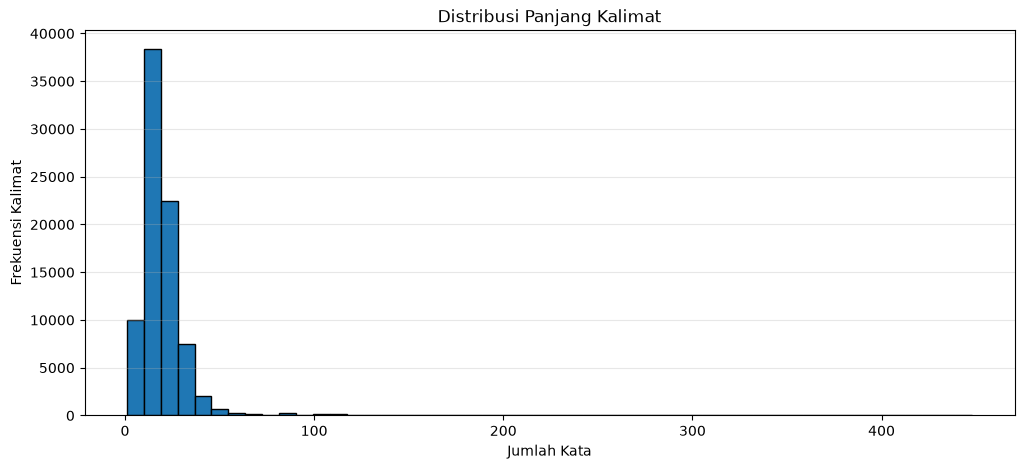

In [50]:
plt.figure(figsize=(12, 5))

plt.hist(
    df_kalimat["n_kata_raw"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribusi Panjang Kalimat")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi Kalimat")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [51]:
df_kalimat["n_kata_raw"] = (
    df_kalimat["kalimat"]
    .astype(str)
    .str.split()
    .str.len()
)

print(df_kalimat["n_kata_raw"].describe().round(2))
print()
print("Kalimat < 4 kata:",(df_kalimat["n_kata_raw"] < 4).sum())
print("Kalimat > 80 kata:",(df_kalimat["n_kata_raw"] > 80).sum())

count    82509.00
mean        19.21
std         13.96
min          1.00
25%         12.00
50%         17.00
75%         23.00
max        448.00
Name: n_kata_raw, dtype: float64

Kalimat < 4 kata: 816
Kalimat > 80 kata: 842


In [55]:
kalimat_pendek = df_kalimat[df_kalimat["n_kata_raw"] < 4]
kalimat_panjang = df_kalimat[df_kalimat["n_kata_raw"] > 80]

cek_fulltext(
    kalimat_panjang,
    "kalimat",
    n=10,
    mode="sample"
)

ID       : 593177
Judul    : Asing Ramai-Ramai Serbu Pasar Saham RI, Emiten Ini Jadi Incaran
Timestamp: 2024-12-04

Fulltext:
Selengkapnya, berikut 10 saham dengan net foreign sell terbesar pada perdagangan kemarin: PT Bank Rakyat Indonesia Tbk (BBRI) Rp 188,09 miliar PT Bank Negara Indonesia Tbk (BBNI) Rp 37,16 miliar PT Indofood CBP Sukses Makmur Tbk (ICBP) Rp 18,41 miliar PT United Tractors Tbk (UNTR) Rp 14,50 miliar PT Timah Tbk (TINS) Rp 13,48 miliar PT Semen Indonesia (Persero) Tbk. (SMGR) - Rp13,24 miliar PT Bumi Resources Tbk. (BUMI) - Rp12,20 miliar PT Indah Kiat Pulp & Paper Tbk. (INKP) - Rp10,86 miliar PT Adaro Minerals Indonesia Tbk. (ADMR) - Rp10,78 miliar PT Avia Avian Tbk. (AVIA) - Rp10,64 miliar

ID       : 744410
Judul    : IHSG Sepekan Melesat 2,82%, Asing Diam-Diam Akumulasi Saham Ini
Timestamp: 2026-06-21

Fulltext:
Berikut daftar 10 saham dengan net buy asing terbesar sepanjang 15-19 Juni 2026: PT Merdeka Gold Resources Tbk (EMAS): Rp3,47 triliun PT Bank Central As

In [ ]:
# hapus noise & boilerplate tersisa
def bersihkan_kalimat(teks):
    teks = unicodedata.normalize("NFC", str(teks))
    teks = invisible.sub("", teks)
    teks = re.sub(r"\s+", " ", teks).strip()

    # Hapus kalimat promosi artikel
    if link_promo.search(teks):
        return ""

    # Hapus dateline di awal kalimat
    teks = dateline.sub("", teks)

    # Hapus bullet atau tanda pemisah di awal
    teks = re.sub(
        r"^\s*[\u2013\u2014\u2022\u00b7-]+\s*",
        "",
        teks
    )

    # Hapus URL
    teks = url.sub(" ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()

    # Hapus kalimat yang seluruhnya merupakan boilerplate,
    # fragment, atau karakter numerik/punctuation
    if (
        not teks
        or footer.fullmatch(teks)
        or disclaimer.fullmatch(teks)
        or fragment.fullmatch(teks)
        or numeric.fullmatch(teks)
        or noise.search(teks)
        or is_listing_noise(teks)
    ):
        return ""

    return teks

In [57]:
# handle kalimat listing 
def is_listing_noise(text):
    if len(kurs.findall(text)) >= 3:
        return True

    if (
        len(kode_emitmen.findall(text)) >= 3
        and len(kurs_rp.findall(text)) >= 3
    ):
        return True

    if re.search(r"Rekomendasi Saham", text, flags=re.I):
        return True

    if len(re.findall(r"\|", text)) >= 2:
        return True

    if re.search(r"\bTP\b.*\bSL\b", text, flags=re.I):
        return True

    return False

In [58]:
bank_per_artikel = {}

for row in raw.itertuples(index=False):
    teks_artikel = f"{row.judul} {row.isi_mentah}"

    bank_per_artikel[row.id_artikel] = deteksi_bank(
        teks_artikel
    )

In [59]:
rows_bersih = []

for row in df_kalimat.itertuples(index=False):

    kalimat_bersih = bersihkan_kalimat(row.kalimat)

    if not kalimat_bersih:
        continue

    n_kata = len(kalimat_bersih.split())

    # Filter panjang kalimat
    if n_kata < 4 or n_kata > 80:
        continue

    rows_bersih.append({
        "id_artikel": row.id_artikel,
        "id_kalimat": row.id_kalimat,
        "bank": bank_per_artikel.get(row.id_artikel, ""),
        "judul": row.judul,
        "timestamp": row.timestamp,
        "kalimat": kalimat_bersih,
        "n_kata": n_kata
    })

kal_semua = pd.DataFrame(rows_bersih)

print("Jumlah kalimat sebelum preprocessing:", len(df_kalimat))
print("Jumlah kalimat setelah preprocessing:", len(kal_semua))

Jumlah kalimat sebelum preprocessing: 82509
Jumlah kalimat setelah preprocessing: 80049


### **Cek missing text**

In [62]:
kal_semua.isnull().sum()

id_artikel    0
id_kalimat    0
bank          0
judul         0
timestamp     0
kalimat       0
n_kata        0
dtype: int64

In [68]:
(kal_semua["kalimat"].astype(str).str.strip() == "").sum()

np.int64(0)

### **Duplicated**

In [64]:
kal_semua.duplicated(subset="kalimat").sum()

np.int64(16422)

In [67]:
jumlah_sebelum_dedup = len(kal_semua)

df_clean = (kal_semua.drop_duplicates(subset="kalimat").reset_index(drop=True))

jumlah_duplikat = jumlah_sebelum_dedup - len(df_clean)

print("Jumlah sebelum dedup :", jumlah_sebelum_dedup)
print("Duplikat dihapus     :", jumlah_duplikat)
print("Jumlah final         :", len(df_clean))

Jumlah sebelum dedup : 80049
Duplikat dihapus     : 16422
Jumlah final         : 63627


## **4. Stopword untuk keyword topik**

Dipakai HANYA untuk representasi keyword c-TF-IDF, bukan teks yang di-embed. Final = (generik Sastrawi + domain finansial) DIKURANGI kata negasi (negasi menentukan arah sentimen).

In [69]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

tokens = []
for k in df_clean["kalimat"]:
    tokens += re.findall(r"[a-zA-Z]+", str(k).lower())
freq = Counter(tokens)
print(f"Total token: {len(tokens):,} | kata unik: {len(freq):,}")

Total token: 1,120,980 | kata unik: 20,688


In [70]:
stop_domain = {"rp", "pt", "tbk", "persero", "miliar", "triliun", "juta", "ribu",
               "i", "ii", "iii", "yoy", "as", "us",
               "senin", "selasa", "rabu", "kamis", "jumat", "sabtu", "minggu",
               "indonesia", "menjadi", "ihsg"}

negasi = {"tidak", "tak", "bukan", "belum", "jangan", "tanpa", "kurang",
          "non", "anti", "minus", "gagal", "batal", "turun", "melemah", "koreksi"}

stop_generik = set(StopWordRemoverFactory().get_stop_words())

In [71]:
stopwords_id = sorted((stop_generik | stop_domain) - negasi)
assert not (set(stopwords_id) & negasi)
print(f"Stopword final untuk vectorizer: {len(stopwords_id)} (negasi dipertahankan)")

Stopword final untuk vectorizer: 144 (negasi dipertahankan)


## **5. BERTopic**

Input = kalimat unik. `min_cluster_size=200`, `random_state=42` (reproducible). Kalimat yang tidak masuk cluster padat tetap menjadi outlier topik `-1`, yang nanti diperlakukan sebagai kategori "Lainnya" saat penamaan aspek (bukan dipaksa masuk topik).

In [ ]:
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic

SEED, MIN_CLUSTER_SIZE, MIN_SAMPLES, MIN_DF = 42, 250, 10, 5
MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"

docs = df_clean["kalimat"].tolist()
print(f"Input BERTopic: {len(docs):,} kalimat unik")


c:\Users\frederick.clarence\anaconda3\envs\text-mining-aol\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


KeyboardInterrupt: 

### **Parameter BERTopic**

In [ ]:
embedding_model = SentenceTransformer(MODEL_NAME)
embeddings = embedding_model.encode(
    docs,
    show_progress_bar=True,
    batch_size=64
)

umap_model = UMAP(
    n_neighbors=15,
    n_components=5, 
    min_dist=0.0,
    metric="cosine",
    random_state=SEED
)

hdbscan_model = HDBSCAN(
    min_cluster_size=MIN_CLUSTER_SIZE,
    min_samples=MIN_SAMPLES,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

vectorizer_model = CountVectorizer(
    stop_words=stopwords_id,
    ngram_range=(1, 2),
    min_df=MIN_DF
)

# Model BERTopic
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    language="multilingual", 
    calculate_probabilities=False,
    verbose=True
)

In [ ]:
topics, probs = topic_model.fit_transform(docs, embeddings)

info = topic_model.get_topic_info()
n_out = int((pd.Series(topics) == -1).sum())
print(f"Jumlah topik (tanpa -1): {sum(info.Topic != -1)} | outlier -1: {n_out:,} ({n_out/len(topics):.1%})")
info.head(40)

## **Simpan Output**

In [ ]:
OUTDIR = Path("data/processed")
OUTDIR.mkdir(parents=True, exist_ok=True)

# OUTPUT 1: seluruh kalimat clean (tanpa duplikat) + topik
kal = df_clean.copy()
kal["topic"] = topics
kal[["id_artikel", "id_kalimat", "bank", "timestamp", "kalimat", "n_kata", "topic"]].to_csv(
    OUTDIR / "sentences_with_topic.csv", index=False)
print(f"[1] sentences_with_topic.csv -> {len(kal):,} kalimat")

# OUTPUT 2: info tiap topik + 3 kalimat representatif
baris = []
for t in info["Topic"].tolist():
    kw = ", ".join(w for w, _ in (topic_model.get_topic(t) or [])[:10])
    if t == -1:
        # topik -1 (outlier): BERTopic tak menyediakan representative docs,
        # ambil 3 contoh kalimat -1 langsung dari data agar tetap bisa dicek
        docs_rep = kal.loc[kal["topic"] == -1, "kalimat"].head(3).tolist()
    else:
        docs_rep = topic_model.get_representative_docs(t) or []
    docs_rep = (docs_rep + ["", "", ""])[:3]
    baris.append({"Topic": t, "Count": int(info.loc[info.Topic == t, "Count"].iloc[0]),
                  "Keywords": kw, "Representative_1": docs_rep[0],
                  "Representative_2": docs_rep[1], "Representative_3": docs_rep[2]})
pd.DataFrame(baris).to_csv(OUTDIR / "topic_info.csv", index=False)
print(f"[2] topic_info.csv -> {len(baris)} baris topik")


[1] sentences_with_topic.csv -> 63,632 kalimat
[2] topic_info.csv -> 47 baris topik
